# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ahlam Idris, Geethan Sundaram, Mahati Vedula

**Date:** 11/11/2026

### Question 1

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
# Clean the data `pierce_county_house_sales.csv` 
df = pd.read_csv('data/pierce_county_house_sales.csv', parse_dates=['sale_date'])

print(df.shape)
df.info()
display(df.head(n=10))
display(df.describe().T)
print("Missing values: ")
display(df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows: ", df.duplicated().sum())

# Categorical data
for col in df.select_dtypes(exclude='number').columns.drop('sale_date'):
    print(f"Column: {col}")
    print(df[col].value_counts(dropna=False))

# Perform some EDA and visualization to get to know the data set.

(16814, 19)
<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   sale_date                    16814 non-null  datetime64[us]
 1   sale_price                   16814 non-null  int64         
 2   house_square_feet            16814 non-null  int64         
 3   attic_finished_square_feet   16814 non-null  int64         
 4   basement_square_feet         16814 non-null  int64         
 5   attached_garage_square_feet  16814 non-null  int64         
 6   detached_garage_square_feet  16814 non-null  int64         
 7   fireplaces                   16814 non-null  int64         
 8   hvac_description             16807 non-null  str           
 9   exterior                     16813 non-null  str           
 10  interior                     16807 non-null  str           
 11  stories                      16814 non-n

,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
5,2020-01-02,250000,989,336,0,0,0,1,Electric Baseboard,Frame Siding,Drywall,1,Composition Shingle,1925,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
6,2020-01-02,360000,2048,0,0,441,0,1,Forced Air,Frame Siding,Drywall,2,Composition Shingle,1998,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
7,2020-01-01,370000,1118,0,0,242,0,0,Electric Baseboard,Frame Siding,Drywall,1,Composition Shingle,1968,3,1,NaN,NaN,SEWER/SEPTIC INSTALLED
8,2020-01-02,485000,978,340,968,0,0,1,Warm and Cool Air Zone,Frame Siding,Drywall,1,Composition Shingle,1925,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
9,2020-01-02,475000,2238,0,0,436,0,1,Heat Pump,Frame Siding,Drywall,2,Composition Shingle,2019,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED


,count,mean,min,25%,50%,75%,max,std
sale_date,16814,2020-07-16 13:34:32.986796,2020-01-01 00:00:00,2020-04-27 00:00:00,2020-07-27 00:00:00,2020-10-09 00:00:00,2020-12-31 00:00:00,NaN
sale_price,16814.0,461233.191507,2000.0,348000.0,416500.0,523806.5,6130000.0,236083.342854
house_square_feet,16814.0,1879.941953,1.0,1320.0,1774.0,2352.0,9510.0,760.419008
attic_finished_square_feet,16814.0,24.945878,0.0,0.0,0.0,0.0,1212.0,102.066417
basement_square_feet,16814.0,167.852861,0.0,0.0,0.0,0.0,4000.0,429.065832
attached_garage_square_feet,16814.0,364.425122,0.0,0.0,420.0,528.0,2816.0,286.454018
detached_garage_square_feet,16814.0,38.298501,0.0,0.0,0.0,0.0,3664.0,164.691471
fireplaces,16814.0,0.889021,0.0,1.0,1.0,1.0,5.0,0.596731
stories,16814.0,1.558285,0.0,1.0,2.0,2.0,3.0,0.512055
year_built,16814.0,1980.469252,1880.0,1959.0,1990.0,2006.0,2021.0,33.339025


Missing values: 


hvac_description        7
exterior                1
interior                7
roof_cover              8
waterfront_type     16261
view_quality        15895
dtype: int64

Duplicate rows:  46
Column: hvac_description
hvac_description
Forced Air                10382
Electric Baseboard         2668
Heat Pump                  2084
Warm and Cool Air Zone     1268
Floor/Wall Furnace          174
Hot Water Baseboard         146
No Heat                      82
NaN                           7
Electric                      2
Floor Wall Furnace            1
Name: count, dtype: int64
Column: exterior
exterior
Frame Siding              14577
Frame Vinyl                1724
Masonry Common Brick        208
Frame Stucco                156
Masonry Concrete Block       43
Finished Cottage             41
Frame Rustic Log             21
Log                          12
Frame Hardboard              11
Cedar Finished Cabin          5
Unfinished Cottage            4
Pine Finished Cabin           4
Cedar A-Frame                 2
Cedar Unfinished Cabin        2
Pine Unfinished Cabin         2
NaN                           1
Pine A-Frame                  1
Name: count, dtype: in

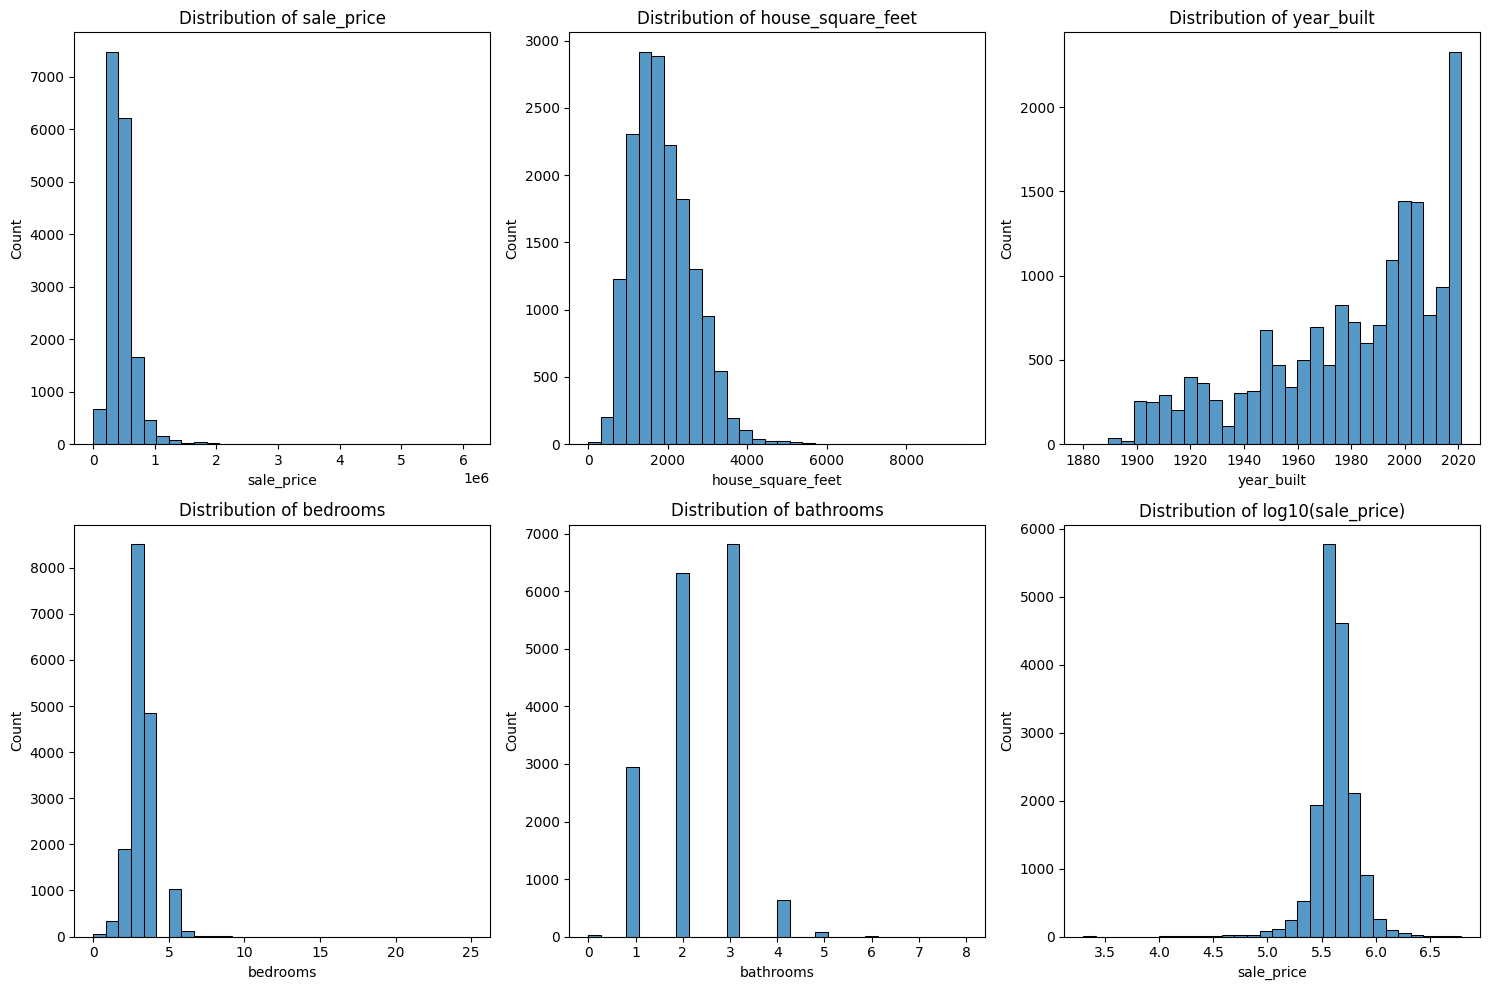

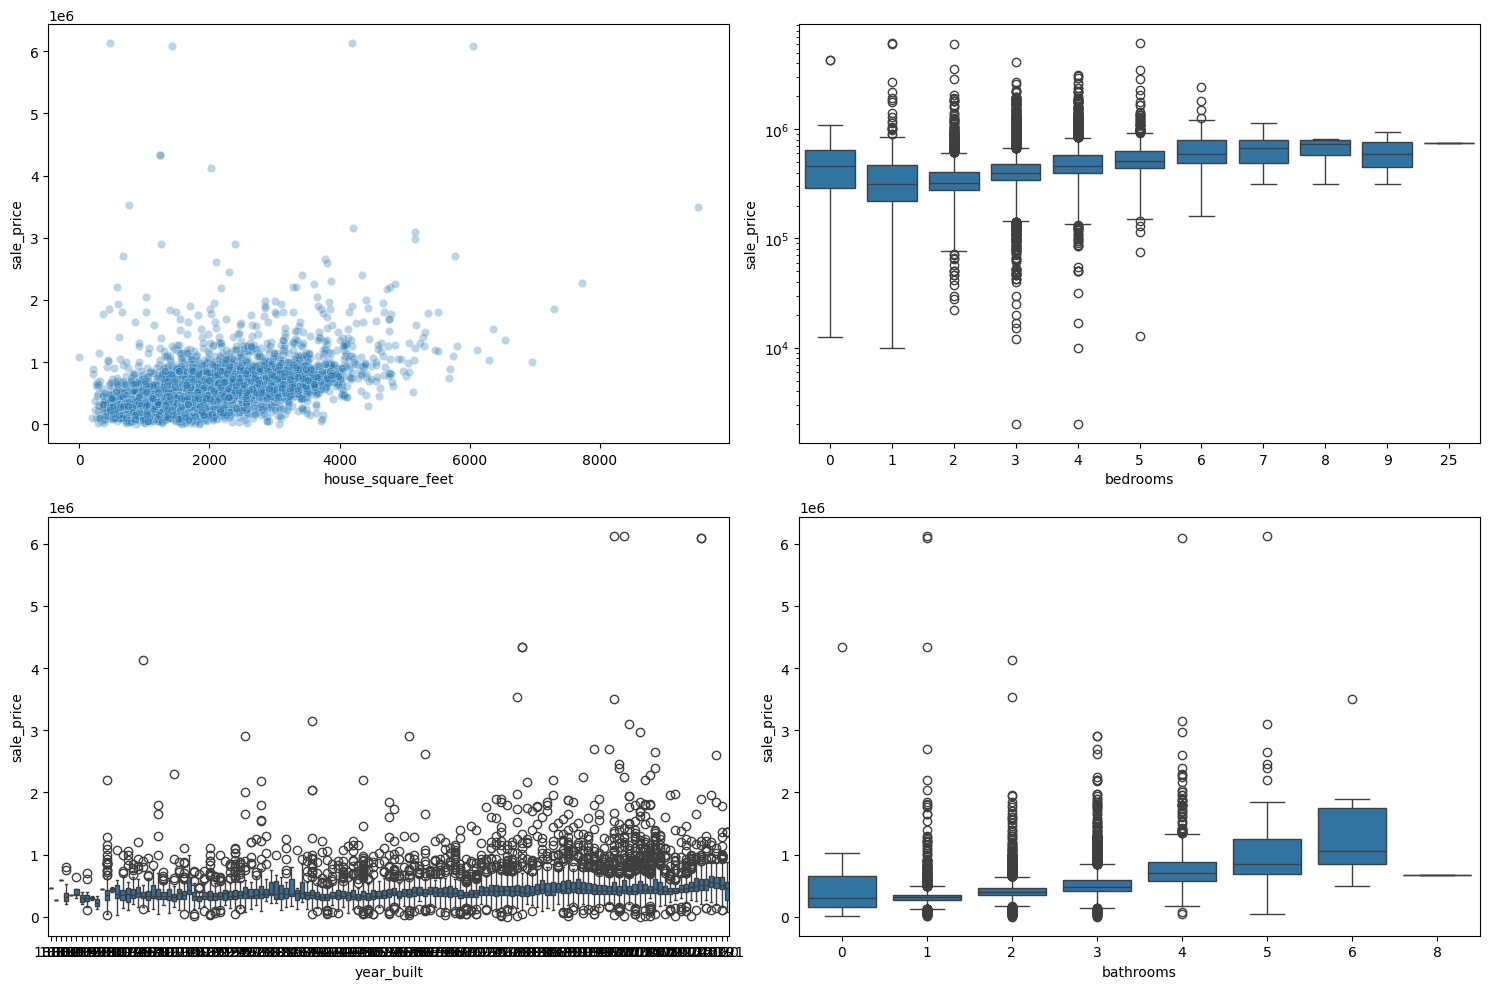

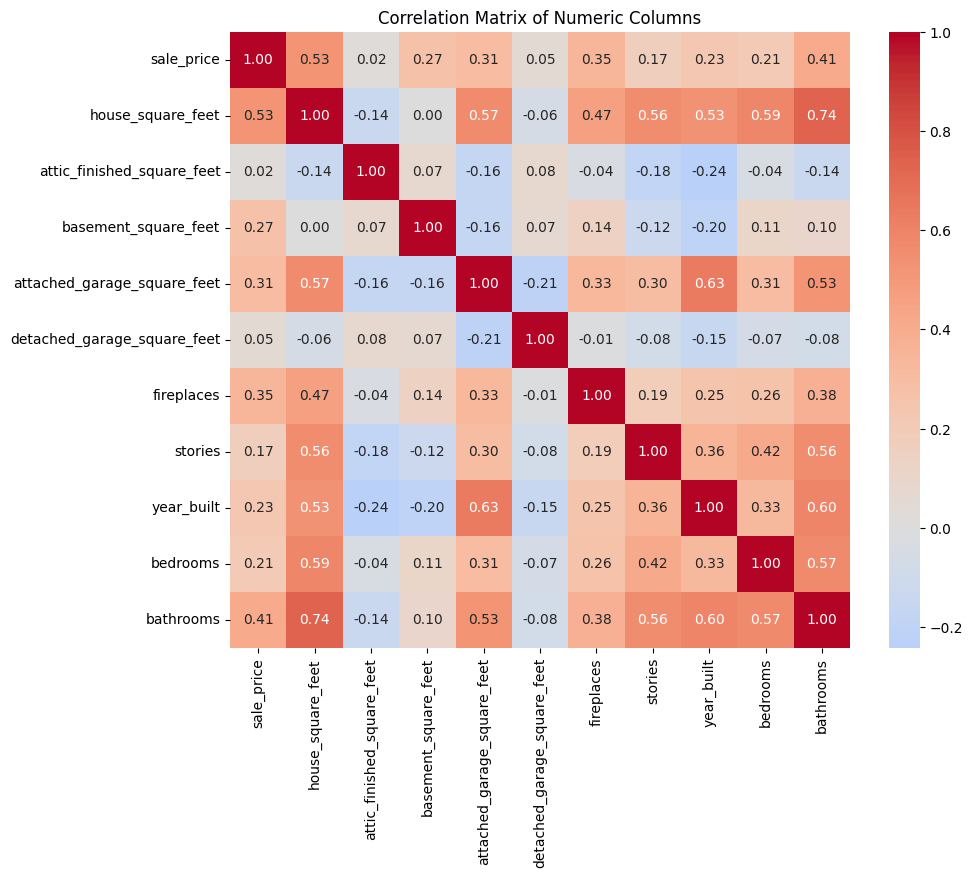

In [54]:
numeric_cols = ['sale_price', 'house_square_feet', 'year_built', 'bedrooms', 'bathrooms']

# Histograms to show numeric column value distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col], ax=i, bins=30)
    i.set_title(f'Distribution of {col}')
sns.histplot(np.log10(df['sale_price']), bins=30, ax=axes.flat[-1])
axes.flat[-1].set_title('Distribution of log10(sale_price)')
plt.tight_layout()
plt.show()

# Scatterplots and boxplots to show relationships between numeric columns and sale_price
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.scatterplot(data=df, x='house_square_feet', y='sale_price', alpha=0.3, ax=axes[0, 0])
sns.boxplot(data=df, x='bedrooms', y='sale_price', ax=axes[0, 1])
sns.boxplot(data=df, x='year_built', y='sale_price', ax=axes[1, 0])
sns.boxplot(data=df, x='bathrooms', y='sale_price', ax=axes[1, 1])
axes[0, 1].set_yscale('log')
plt.tight_layout()
plt.show()

# Correlation matrix to show relationships between numeric columns
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes('number').corr(), annot = True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Numeric Columns')
plt.show()


In [55]:
# Cleaning data based on discoveries in EDA
clean = df.copy()
clean = clean.drop_duplicates()

# Filling in missing values
clean['waterfront_type'] = clean['waterfront_type'].fillna('None')
clean['view_quality'] = clean['view_quality'].fillna('None')

# Dropping rows with few missing values + standardizing value labels
clean = clean.dropna(subset=['hvac_description', 'exterior', 'interior', 'roof_cover'])
clean['hvac_description'] = clean['hvac_description'].replace(
    {'Floor Wall Furnace': 'Floor/Wall Furnace'})
clean['exterior'] = clean['exterior'].replace({'Log': 'Frame Rustic Log'})

clean['sewer_installed'] = clean['utility_sewer'].eq('SEWER/SEPTIC INSTALLED')
clean = clean.drop(columns='utility_sewer')

# Removing values that don't make sense
bad = (
    (clean['bedrooms'] == 0)
    | (clean['bathrooms'] == 0)
    | (clean['stories'] == 0)
)
print(f"Non-sensical rows: {bad.sum()}")
display(clean[bad].sample(10, random_state=1))
clean = clean[~bad]

# Removing extreme right-skewed outliers for price per house_square_feet (as seen in earlier histogram)
clean['price_per_sqft'] = clean['sale_price'] / clean['house_square_feet']
low, high = clean['price_per_sqft'].quantile([0.005, 0.995])
clean = clean[clean['price_per_sqft'].between(low, high)]

print(f"Rows: {len(df)} raw -> {len(clean)} cleaned")

Non-sensical rows: 73


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,sewer_installed
4656,2020-05-13,600000,1440,0,0,0,0,0,Electric Baseboard,Frame Siding,Drywall,2,Composition Shingle,1997,0,1,None,View Lim,True
13349,2020-10-28,330000,360,0,0,0,0,1,No Heat,Finished Cottage,Drywall,1,Composition Shingle,1950,0,0,WF Salt,None,True
2226,2020-03-10,416144,2490,0,0,580,0,1,Heat Pump,Frame Siding,Drywall,0,Composition Shingle,2020,4,3,None,None,True
16375,2020-12-17,1139900,3767,0,0,735,0,2,Heat Pump,Frame Siding,Drywall,0,Composition Shingle,2020,5,4,None,View Lim -,True
13301,2020-10-28,250000,356,0,462,0,0,0,Electric Baseboard,Frame Siding,Drywall,1,Composition Shingle,1921,0,1,None,None,True
5841,2020-06-10,499000,2160,0,0,504,0,1,Heat Pump,Frame Siding,Drywall,1,Composition Shingle,2017,0,0,None,None,True
10048,2020-08-07,619950,2823,0,315,441,0,1,Warm and Cool Air Zone,Frame Siding,Drywall,0,Composition Shingle,2020,4,3,None,None,True
7904,2020-07-22,160000,600,0,0,0,0,0,Electric Baseboard,Frame Siding,Drywall,1,Composition Shingle,1950,1,0,WF Lake,None,False
8763,2020-08-03,150000,490,0,0,0,0,0,No Heat,Frame Siding,Drywall,1,Composition Shingle,1910,0,0,WF Salt,None,False
14432,2020-11-16,625000,1120,144,0,1120,0,0,Floor/Wall Furnace,Frame Siding,Drywall,0,Composition Shingle,1922,0,0,None,None,True


Rows: 16814 raw -> 16510 cleaned


(16510, 20)
<class 'pandas.DataFrame'>
Index: 16510 entries, 0 to 16813
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   sale_date                    16510 non-null  datetime64[us]
 1   sale_price                   16510 non-null  int64         
 2   house_square_feet            16510 non-null  int64         
 3   attic_finished_square_feet   16510 non-null  int64         
 4   basement_square_feet         16510 non-null  int64         
 5   attached_garage_square_feet  16510 non-null  int64         
 6   detached_garage_square_feet  16510 non-null  int64         
 7   fireplaces                   16510 non-null  int64         
 8   hvac_description             16510 non-null  str           
 9   exterior                     16510 non-null  str           
 10  interior                     16510 non-null  str           
 11  stories                      16510 non-null  

,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,sewer_installed,price_per_sqft
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,None,None,True,176.170607
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,None,None,True,171.134942
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,None,None,True,289.187328
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,None,None,True,302.475962
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,None,None,True,280.898876
5,2020-01-02,250000,989,336,0,0,0,1,Electric Baseboard,Frame Siding,Drywall,1,Composition Shingle,1925,2,1,None,None,True,252.780586
6,2020-01-02,360000,2048,0,0,441,0,1,Forced Air,Frame Siding,Drywall,2,Composition Shingle,1998,4,3,None,None,True,175.781250
7,2020-01-01,370000,1118,0,0,242,0,0,Electric Baseboard,Frame Siding,Drywall,1,Composition Shingle,1968,3,1,None,None,True,330.948122
8,2020-01-02,485000,978,340,968,0,0,1,Warm and Cool Air Zone,Frame Siding,Drywall,1,Composition Shingle,1925,3,2,None,None,True,495.910020
9,2020-01-02,475000,2238,0,0,436,0,1,Heat Pump,Frame Siding,Drywall,2,Composition Shingle,2019,3,3,None,None,True,212.243074


,count,mean,min,25%,50%,75%,max,std
sale_date,16510,2020-07-16 12:36:22.241066,2020-01-01 00:00:00,2020-04-27 00:00:00,2020-07-27 00:00:00,2020-10-09 00:00:00,2020-12-31 00:00:00,NaN
sale_price,16510.0,457780.409146,45000.0,349950.0,416725.0,520000.0,3500000.0,200640.466237
house_square_feet,16510.0,1886.960933,200.0,1328.0,1778.0,2355.0,9510.0,753.856997
attic_finished_square_feet,16510.0,24.794125,0.0,0.0,0.0,0.0,1212.0,101.747144
basement_square_feet,16510.0,168.272562,0.0,0.0,0.0,0.0,4000.0,428.790488
attached_garage_square_feet,16510.0,365.909449,0.0,0.0,424.0,528.0,2816.0,285.56554
detached_garage_square_feet,16510.0,38.265233,0.0,0.0,0.0,0.0,3664.0,164.482495
fireplaces,16510.0,0.893519,0.0,1.0,1.0,1.0,5.0,0.593788
stories,16510.0,1.564082,1.0,1.0,2.0,2.0,3.0,0.507363
year_built,16510.0,1980.532223,1880.0,1959.0,1990.0,2006.0,2021.0,33.280419


Missing values: 


Series([], dtype: int64)

Duplicate rows:  0
Column: hvac_description
hvac_description
Forced Air                10254
Electric Baseboard         2585
Heat Pump                  2047
Warm and Cool Air Zone     1259
Floor/Wall Furnace          166
Hot Water Baseboard         142
No Heat                      56
Electric                      1
Name: count, dtype: int64
Column: exterior
exterior
Frame Siding              14351
Frame Vinyl                1701
Masonry Common Brick        204
Frame Stucco                155
Masonry Concrete Block       41
Frame Rustic Log             30
Finished Cottage             13
Frame Hardboard               9
Cedar A-Frame                 2
Cedar Finished Cabin          2
Pine Finished Cabin           1
Pine A-Frame                  1
Name: count, dtype: int64
Column: interior
interior
Drywall     16493
Paneling       17
Name: count, dtype: int64
Column: roof_cover
roof_cover
Composition Shingle    15522
Concrete Tile            300
Built Up Rock            230
Formed Seam Meta

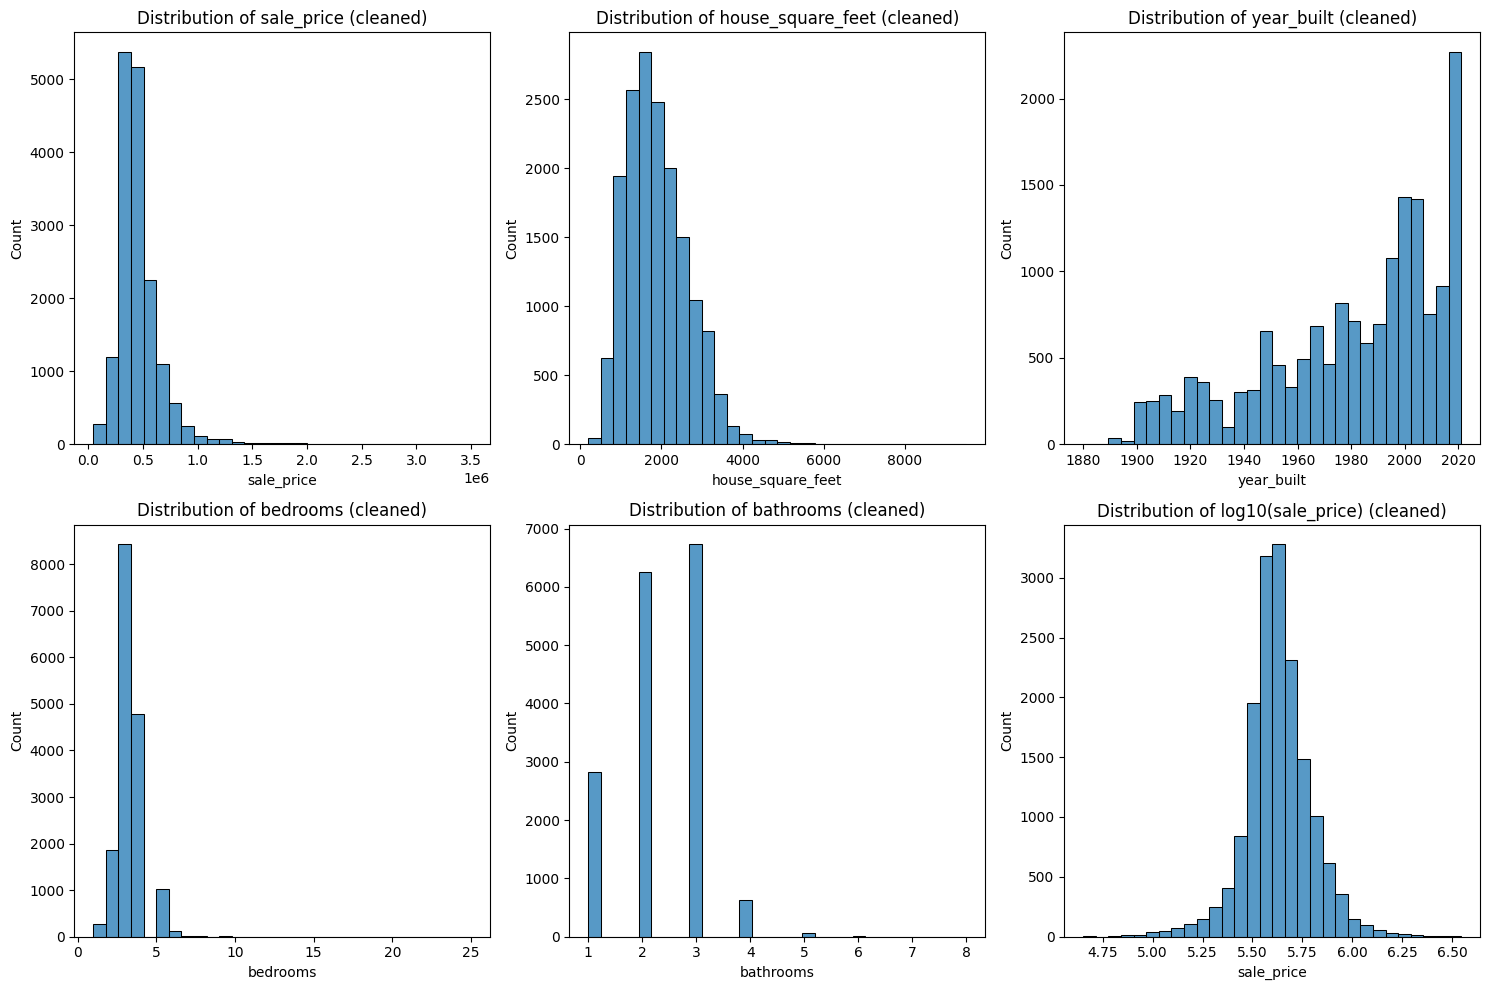

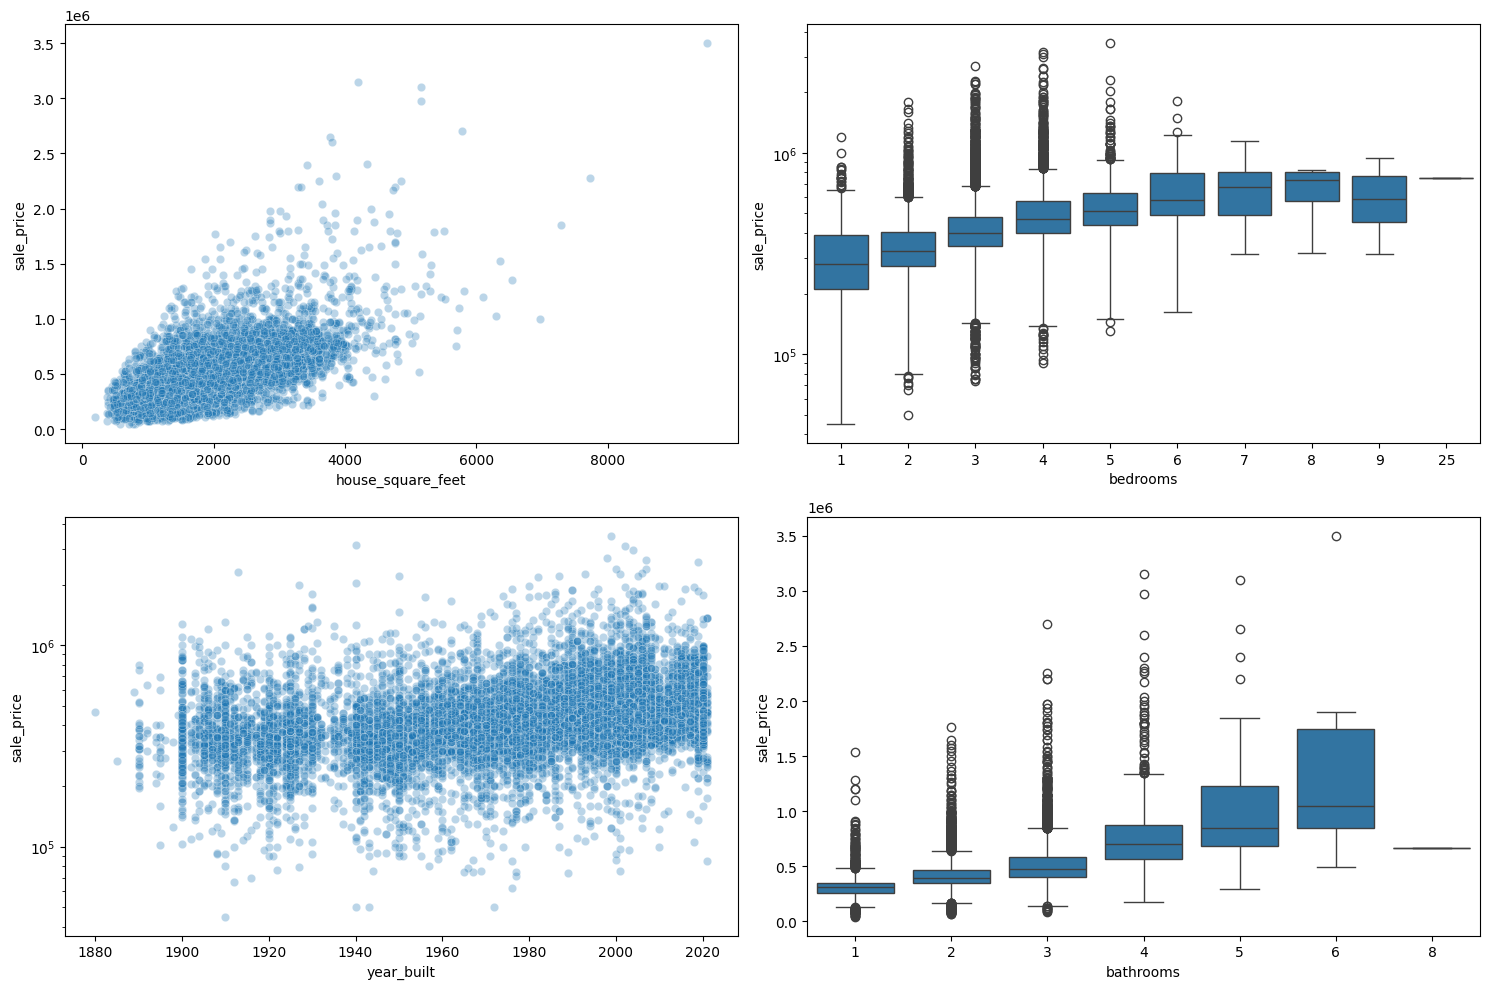

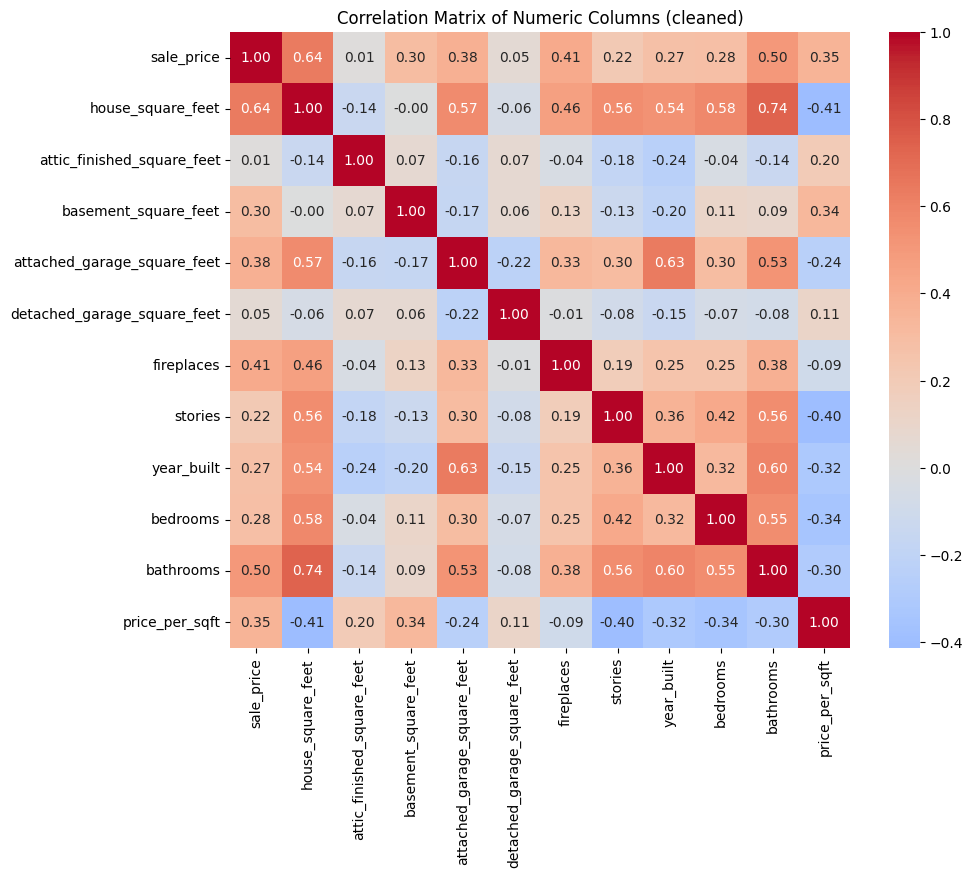

In [56]:
# EDA on cleaned data

print(clean.shape)
clean.info()
display(clean.head(n=10))
display(clean.describe().T)
print("Missing values: ")
display(clean.isna().sum()[clean.isna().sum() > 0])
print("Duplicate rows: ", clean.duplicated().sum())

# Categorical data
for col in clean.select_dtypes(exclude='number').columns.drop('sale_date'):
    print(f"Column: {col}")
    print(clean[col].value_counts(dropna=False))

numeric_cols = ['sale_price', 'house_square_feet', 'year_built', 'bedrooms', 'bathrooms']

# Histograms to show numeric column value distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i, col in zip(axes.flat, numeric_cols):
    sns.histplot(clean[col], ax=i, bins=30)
    i.set_title(f'Distribution of {col} (cleaned)')
sns.histplot(np.log10(clean['sale_price']), bins=30, ax=axes.flat[-1])
axes.flat[-1].set_title('Distribution of log10(sale_price) (cleaned)')
plt.tight_layout()
plt.show()

# Scatterplots and boxplots to show relationships with sale_price
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.scatterplot(data=clean, x='house_square_feet', y='sale_price', alpha=0.3, ax=axes[0, 0])
sns.boxplot(data=clean, x='bedrooms', y='sale_price', ax=axes[0, 1])
sns.scatterplot(data=clean, x='year_built', y='sale_price', alpha=0.3, ax=axes[1, 0])
sns.boxplot(data=clean, x='bathrooms', y='sale_price', ax=axes[1, 1])
axes[0, 1].set_yscale('log')
axes[1, 0].set_yscale('log')
plt.tight_layout()
plt.show()

# Correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(clean.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Numeric Columns (cleaned)')
plt.show()

### Question 2

In [57]:
# Transform your variables - particularly categorical ones - for use in your regression analysis
numeric_cols = [
    'house_square_feet', 'attic_finished_square_feet', 'basement_square_feet',
    'attached_garage_square_feet', 'detached_garage_square_feet',
    'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms',
]
model_df = clean[['sale_price'] + numeric_cols].copy()

# Transforming binary categoricals
model_df['sewer_installed'] = clean['sewer_installed'].astype(int)
model_df['paneling_interior'] = (clean['interior'] == 'Paneling').astype(int)

# Natural order progression
view_order = {
    'None': 0, 'View Lim -': 1, 'View Lim': 2, 'View Lim +': 3,
    'View Avg': 4, 'View Avg +': 5, 'View Good': 6, 'View Good +': 7,
    'View V-Good': 8,
}
model_df['view_score'] = clean['view_quality'].map(view_order)

# One-hot encoding variables, with rarer/similar values grouped together
exterior_map = {
    'Frame Siding': 'Frame Siding', 'Frame Vinyl': 'Frame Vinyl',
    'Frame Stucco': 'Frame Stucco',
    'Masonry Common Brick': 'Masonry', 'Masonry Concrete Block': 'Masonry',
}

categories = pd.DataFrame({
    'exterior': clean['exterior'].map(exterior_map).fillna('Other'),
    'hvac': clean['hvac_description'].replace({
        'Floor/Wall Furnace': 'Other', 'Hot Water Baseboard': 'Other',
        'No Heat': 'Other', 'Electric': 'Electric Baseboard'}),
    'roof': clean['roof_cover'].replace({
        'Formed Seam Metal': 'Metal', 'Preformed Metal': 'Metal'}),
    'waterfront': clean['waterfront_type'],
})

# Drop most common value for each categorical variable to avoid multicollinearity
base = {'exterior': 'Frame Siding', 'hvac': 'Forced Air',
             'roof': 'Composition Shingle', 'waterfront': 'None'}

dummies = pd.get_dummies(categories, dtype=int)
dummies = dummies.drop(columns = [f'{col}_{lvl}' for col, lvl in base.items()])
dummies.columns = [c.replace(' ', '_').replace('/', '_') for c in dummies.columns]

X = pd.concat([model_df.drop(columns='sale_price'), dummies], axis=1)
y = model_df['sale_price']

display(X.head(n=10))

,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms,...,hvac_Other,hvac_Warm_and_Cool_Air_Zone,roof_Built_Up_Rock,roof_Concrete_Tile,roof_Metal,roof_Wood_Shake,waterfront_WF_Lake,waterfront_WF_River,waterfront_WF_Salt,waterfront_WF_Stream_Creek
0,2157,0,0,528,0,0,2,1993,3,3,...,0,1,0,0,0,0,0,0,0,0
1,2238,0,0,396,0,0,2,2017,4,3,...,0,0,0,0,0,0,0,0,0,0
2,1452,0,0,0,0,1,1,1965,3,2,...,0,0,1,0,0,0,0,0,0,0
3,832,0,0,0,0,0,1,1919,2,1,...,0,0,0,0,0,0,0,0,0,0
4,1780,0,384,484,0,1,1,1955,3,2,...,0,0,0,0,0,0,0,0,0,0
5,989,336,0,0,0,1,1,1925,2,1,...,0,0,0,0,0,0,0,0,0,0
6,2048,0,0,441,0,1,2,1998,4,3,...,0,0,0,0,0,0,0,0,0,0
7,1118,0,0,242,0,0,1,1968,3,1,...,0,0,0,0,0,0,0,0,0,0
8,978,340,968,0,0,1,1,1925,3,2,...,0,1,0,0,0,0,0,0,0,0
9,2238,0,0,436,0,1,2,2019,3,3,...,0,0,0,0,0,0,0,0,0,0


### Question 3

In [58]:
# Implement an 80/20 train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape, y_test.shape)

Train: (13208, 29) (13208,)
Test:  (3302, 29) (3302,)


### Question 4

In [59]:
# Build some simple linear models that include no transformations or interactions


# Fit them, and determine their RMSE and $R^2$ on the both the training and test sets.

ANSWER [Which of your models does the best?]

### Question 5

In [60]:
# Make partial correlation plots for each of the numeric variables in your model.

ANSWER [Do you notice any significant non-linearities?]

### Question 6

In [61]:
# Include transformations and interactions of your variables


# Build a more complex model that reflects your ideas about how the features of the asset determine its value. 


# Determine its RMSE and $R^2$ on the training and test sets. 

ANSWER [How does the more complex model your build compare to the simpler ones?]

### Question 7

ANSWER [Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?]

### Question 8

In [62]:
# Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features


# Find the RMSE and $R^2$

ANSWER [Which does it select? What are the RMSE and $R^2$?]

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [63]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]